# AI – Demand forecast, purchase plan and allocation plan
**Question:** how many pieces will we sell next quarter, per category and channel – and therefore what should we buy and send to each branch?
This replaces the two random decisions found in cards 05 and 06 (fixed purchases, fixed transfers).
The code lives in `core/forecast.py` (one place, used by this notebook, the dashboard and the website).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

files = pd.read_pickle('../clean/cottonil_clean.pkl')

# colours: blue = main, grey = context, orange = the ONE thing each chart wants you to look at
BLUE, ORANGE, AQUA, GREY, LIGHT, INK = '#2a78d6', '#eb6834', '#1baf7a', '#b5b4ae', '#b9d3f2', '#52514e'
plt.rcParams.update({'font.size': 10.5, 'axes.titlesize': 12.5, 'axes.titleweight': 'bold', 'axes.edgecolor': '#d6d5d0',
                     'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK, 'figure.dpi': 110})


def style(ax, title, ylabel=None):
    """Title = the insight, light grid, no box."""
    ax.set_title(title, loc='left', pad=12)
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    ax.grid(axis='y', color='#ecebe7'); ax.set_axisbelow(True)
    if ylabel:
        ax.set_ylabel(ylabel)


def save(fig, name):
    fig.savefig(f'../outputs/charts/{name}.png', dpi=150, bbox_inches='tight')


def full_years(d, col='fy'):
    """Complete fiscal years only: FY2019 → FY2026 (Oct–Sep)."""
    return d[(d[col] >= 2019) & (d[col] <= 2026)]


M = lambda x: f'{x / 1e6:,.1f}M'

import sys
sys.path.insert(0, '..')
from core import analytics as A
from core import forecast as F
c = files

In [2]:
m = F.monthly(c)
print('series:', m.groupby(F.KEYS).ngroups, '(16 categories × 3 channels) | months:', m.month.nunique(), f'({m.month.min():%b %Y} → {m.month.max():%b %Y})')
F.add_features(m)[F.KEYS + ['month', 'units'] + F.FEATURES[:6]].dropna().tail(4)

series: 48 (16 categories × 3 channels) | months: 95 (Nov 2018 → Sep 2026)


,category_en,channel,month,units,lag1,lag2,lag3,lag12,roll3,roll12
4556,Women underwear,Wholesale,2026-06-01,182,243.0,309.0,187.0,194.0,246.333333,215.250000
4557,Women underwear,Wholesale,2026-07-01,98,182.0,243.0,309.0,205.0,244.666667,214.250000
4558,Women underwear,Wholesale,2026-08-01,228,98.0,182.0,243.0,226.0,174.333333,205.333333
4559,Women underwear,Wholesale,2026-09-01,108,228.0,98.0,182.0,76.0,169.333333,205.500000


**Features** = what the model looks at: the last 3 months (`lag1–3`), the same month last year (`lag12` = seasonality),
3- and 12-month averages, the month number, a time trend, the category and the channel.
**log1p / expm1**: wholesale months are much bigger than small categories online; the log puts them on a similar scale, then we convert back.

## Backtest – would we have trusted it?
We hide the last 6 months (Apr–Sep 2026), train on everything before, forecast the 6 months **one month at a time**
(each forecast becomes history for the next month), and compare with the simple rule *same month last year*.

WAPE model: 8.8%  |  WAPE 'same month last year': 11.2%  →  the model is 21% more accurate


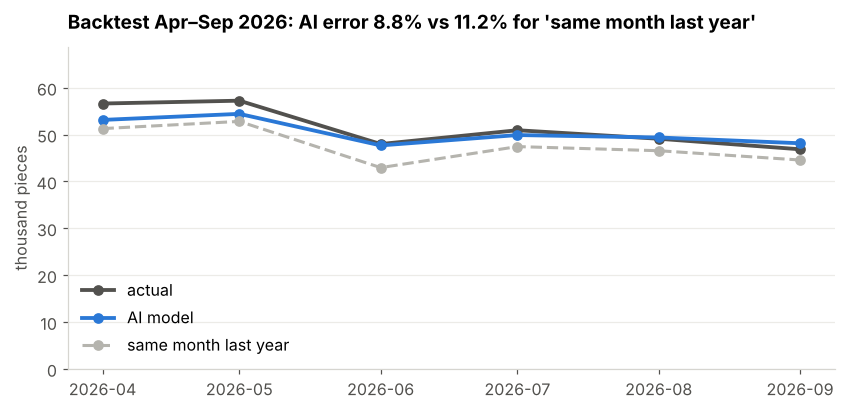

,units,model,naive
month,,,
2026-04-01,56629,53132.0,51279
2026-05-01,57237,54424.0,52814
2026-06-01,47987,47691.0,42952
2026-07-01,50931,49902.0,47439
2026-08-01,49114,49380.0,46558
2026-09-01,46864,48151.0,44574


In [3]:
res, bt = F.backtest(c)
print(f"WAPE model: {res['wape_model']}%  |  WAPE 'same month last year': {res['wape_naive']}%  →  the model is {res['better_%']:.0f}% more accurate")
tot = bt.groupby('month')[['units', 'model', 'naive']].sum()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(tot.index, tot.units / 1e3, color=INK, lw=2.5, marker='o', label='actual')
ax.plot(tot.index, tot.model / 1e3, color=BLUE, lw=2.5, marker='o', label='AI model')
ax.plot(tot.index, tot.naive / 1e3, color=GREY, lw=2, ls='--', marker='o', label='same month last year')
ax.legend(frameon=False); ax.set_ylim(0, tot.values.max() / 1e3 * 1.2)
style(ax, f"Backtest Apr–Sep 2026: AI error {res['wape_model']}% vs {res['wape_naive']}% for 'same month last year'", 'thousand pieces')
save(fig, 'ai_backtest')
tot.round(0)

'Same month last year' misses the growth (+9% a year), so it is always too low. The model learns both the season and the trend.

In [4]:
fc, hist = F.forecast(c, horizon=4)
start, fq = F.next_months(fc)
print(f'the forecast starts in {fc.month.min():%b %Y} (data is complete to Sep 2026); today is Nov 2026 → plan window {start:%b %Y} – {fq.month.max():%b %Y}')
q = fq.pivot_table(index='category_en', columns=fq.month.dt.strftime('%b %Y'), values='units', aggfunc='sum')
q = q[sorted(q.columns, key=lambda s: pd.Timestamp('1 ' + s))]
q['next 3 months'] = q.sum(axis=1)
print('forecast for the plan window:', f"{q['next 3 months'].sum():,.0f} pieces")
q.sort_values('next 3 months', ascending=False).round(0).head(8)

the forecast starts in Oct 2026 (data is complete to Sep 2026); today is Nov 2026 → plan window Nov 2026 – Jan 2027
forecast for the plan window: 173,385 pieces


month,Nov 2026,Dec 2026,Jan 2027,next 3 months
category_en,,,,
Socks,14734.0,14772.0,12938.0,42444.0
Men tops,8156.0,8697.0,7124.0,23976.0
Men boxers,6680.0,7264.0,5667.0,19611.0
Women tops,6706.0,6515.0,5322.0,18543.0
Kids underwear,5292.0,5491.0,4709.0,15493.0
Men underwear,3536.0,3605.0,3083.0,10224.0
Girls pajamas,2904.0,3014.0,2508.0,8427.0
Boys pajamas,2782.0,2955.0,2569.0,8306.0


## Purchase plan
`to buy = forecast for 3 months + safety stock`. Safety stock = 1.65 × monthly standard deviation (95% service level, ~1-month lead time).
We do **not** subtract the stock on hand by default, because the stock count is not reliable (card 05). The dashboard has a switch to subtract it once the count is confirmed.

In [5]:
plan, alloc = F.plans(c, fc, hist)
print(f"plan: buy {plan.to_buy.sum():,.0f} pieces next quarter | the current pattern buys {plan.current_pattern_buys.sum():,.0f} per quarter")
plan.to_csv('../outputs/purchase_plan_next_quarter.csv', encoding='utf-8-sig')
plan.round(0).head(8)

plan: buy 183,066 pieces next quarter | the current pattern buys 10,497,447 per quarter


,forecast_3m,safety_stock,stock_on_hand,to_buy,current_pattern_buys,months_of_stock
Socks,42444.0,2401.0,138476,44845.0,5689211.0,10.0
Men tops,23976.0,1131.0,78603,25107.0,653567.0,10.0
Men boxers,19611.0,960.0,117320,20571.0,504598.0,18.0
Women tops,18543.0,986.0,126436,19529.0,549456.0,20.0
Kids underwear,15493.0,818.0,127568,16311.0,609111.0,25.0
Men underwear,10224.0,670.0,129873,10894.0,387513.0,38.0
Girls pajamas,8427.0,545.0,113327,8972.0,309932.0,40.0
Boys pajamas,8306.0,310.0,105818,8616.0,290586.0,38.0


## Allocation plan (next month = November 2026, per branch × category)
November's forecast for each category, split by each branch's share of that category in FY2026, + 10% safety.

In [6]:
alloc.to_csv('../outputs/allocation_plan_next_month.csv', index=False, encoding='utf-8-sig')
print(f"send next month: {alloc.send_next_month.sum():,.0f} pieces | FY2026 average month: {alloc.sent_per_month_FY2026.sum():,.0f}")
by_cat = alloc.groupby('category_en')[['send_next_month', 'sent_per_month_FY2026']].sum().sort_values('sent_per_month_FY2026', ascending=False)
by_cat.round(0).head(6)

send next month: 65,946 pieces | FY2026 average month: 126,459


,send_next_month,sent_per_month_FY2026
category_en,,
Socks,16210.0,69919.0
Men tops,8970.0,8303.0
Kids underwear,5825.0,7068.0
Women tops,7376.0,6473.0
Men boxers,7350.0,6231.0
Women bras,3010.0,4917.0


### Takeaway
- The AI forecast is **~21% more accurate** than "same month last year" (WAPE 8.8% vs 11.2% on 6 hidden months).
- Next quarter (Nov 2026 – Jan 2027): **~173K pieces** of demand → buy ~183K with safety stock, instead of the ~10.5M a quarter the current pattern buys.
- In November, branches need ~66K pieces (peak month) instead of the ~126K sent per month in FY2026 – and socks drop the most.